<a href="https://colab.research.google.com/github/federico2018lc/Estudio_Dataset_MedicalCostPersonal-Datasets_Kaggle/blob/main/EA3_Sistema_predictivo_de_gastos_m%C3%A9dicos_para_F%C3%A9nix_Medical_Tech.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PROYECTO**: Sistema predictivo de gastos médicos para Fénix Medical Tech (EA1; EA2)

Materias: TesteoSoftware/ Prácticasprofesionalizantes

Profesores a cargo: David Cabrera/Carolina Ahumada/ Flor Garcia Zavia

Integrantes: Grupo Pi

Mariela Yacci		marielayacci@gmail.com; Emanuel Toledo 		j.emanuel.toledo@gmail.com; Federico López Coria		federico2018lc@gmail.com; Marcela Luciana Knecht		lumik1984cva@gmail.com; Matias Rovaretti 		rovarettimatias123@gmail.com

##  1. EDA: Análisis exploratorio de los datos

La comprensión de los datos se organiza como una secuencia de tareas. El objetivo no es solamente observar el dataset, sino entender su origen, su estructura, sus variables y su calidad antes de realizar transformaciones o construir modelos.

### 1.1 Recolección de datos iniciales
- El origen de los datos.
- El contexto en el que fueron obtenidos.
- Las posibles limitaciones del dataset.


Para el proyecto se utiliza el dataset **Medical Cost Personal Datasets**, disponible en Kaggle.

**Fuente:** [Medical Cost Personal Datasets — Kaggle]
https://www.kaggle.com/datasets/mirichoi0218/insurance/data

El conjunto de datos contiene información individual relacionada con características personales y costos médicos.
Carga del dataset y librerías

A continuación se importan las librerías necesarias y se carga el dataset que se utilizará durante el análisis.

Esta celda establece el entorno de trabajo y permite verificar inicialmente las dimensiones del conjunto de datos.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
import plotly.express as px
import warnings
import plotly.express as px
warnings.filterwarnings("ignore")
#
url='https://raw.githubusercontent.com/federico2018lc/Estudio_Dataset_MedicalCostPersonal-Datasets_Kaggle/refs/heads/main/insurance.csv'
df= pd.read_csv(url,sep=',')
df.shape


(1338, 7)

### 1.2 Descripción de los datos

- La cantidad total de filas y columnas.
- Los nombres de las variables.
- Los tipos de datos presentes en cada columna.

Esta revisión permite comprender la estructura básica del conjunto de datos antes de continuar con análisis más específicos.


 **Diccionario de datos**


El dataset contiene las siguientes variables:
Edad: números enteros  - variable cuantitativa discreta

Sex: variable categorica  

bmi:  numeros con decimales - variable cuantitativa continua

Children (hijos): variable cuantitativa discreta

Smoker (fumador): variable categorica nominal

Region: variable categorica nominal

charges: (costos medicos): varialbe cuantitativa continua





| Variable | Descripción | Tipo de variable |
|---|---|---|
| `age` | Edad de la persona, expresada en años. | Cuantitativa discreta |
| `sex` | Sexo registrado de la persona. | Categórica nominal |
| `bmi` | Índice de masa corporal (*Body Mass Index*). | Cuantitativa continua |
| `children` | Cantidad de hijos o personas dependientes consideradas en el registro. | Cuantitativa discreta |
| `smoker` | Indica si la persona es fumadora. | Categórica nominal |
| `region` | Región geográfica de residencia. | Categórica nominal |
| `charges` | Costos médicos individuales registrados. | Cuantitativa continua |

Este diccionario facilita la interpretación de las variables utilizadas en las etapas posteriores del análisis.



In [ ]:
#primeras filas
df.head(10)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [ ]:
#cuantas filas y columnas hay
print('Total filas: ',df.shape[0])
print('Total colmumnas: ',df.shape[1])

Total filas:  1338
Total colmumnas:  7


In [ ]:
#como se llaman las columnas ( por si luego necestamos copiarlas y/o cambiar)
list(df.columns)

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

In [ ]:
#ahora, info general para luego ver los tipos de variables que tenemos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Nota: Tenemos 1338 datos no nulos por cada columna. Como la cantidad de filas era 1338, podemos observa que **no hay datos nulos.** (eso no quiere decir que los datos sean correctos)

### 1.3 Estadística descriptiva.

La exploración permite conocer el comportamiento de las variables y detectar relaciones relevantes. Puede incluir: Estadística descriptiva básica Distribuciones de variables. Relaciones entre variables. Visualizaciones mediante histogramas, boxplots y gráficos de dispersión.

Estadística sobre Variables Numéricas

In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Las variables numéricas presentan escalas y comportamientos diferentes. `age` se concentra alrededor de los 39 años, `bmi` alrededor de 30,7 y `children` tiene una mediana de 1. En `charges` la media es mayor que la mediana, lo que anticipa una distribución asimétrica hacia valores altos y justifica revisar posibles valores atípicos.


**Variable a Predecir: `Charges`**


Costos médicos individuales registrados.

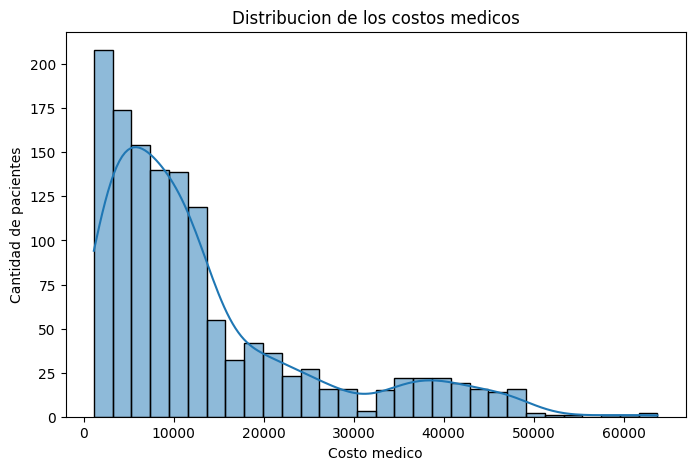

In [ ]:
#visualizamos como estan distribuidos los costos medicos
plt.figure(figsize=(8,5))

sns.histplot(df["charges"],kde=True)
plt.title("Distribucion de los costos medicos")
plt.xlabel("Costo medico")
plt.ylabel("Cantidad de pacientes")

plt.show()

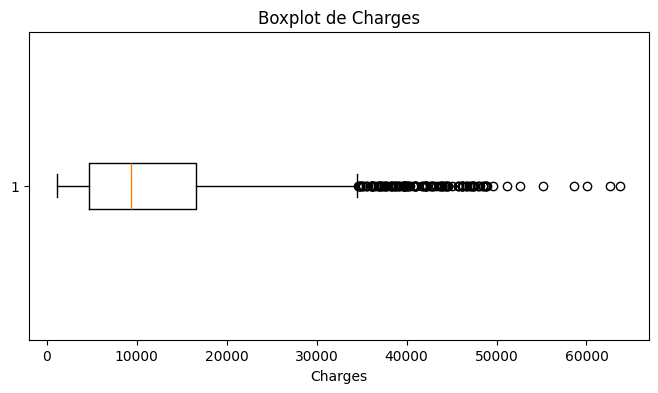

In [ ]:
plt.figure(figsize=(8, 4))

plt.boxplot(df["charges"], vert=False)

plt.title("Boxplot de Charges")
plt.xlabel("Charges")

plt.show()

In [ ]:
# Cuantificamos posibles valores atípicos de la variable objetivo mediante el criterio del IQR
q1 = df["charges"].quantile(0.25)
q3 = df["charges"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_charges = df[
    (df["charges"] < limite_inferior) |
    (df["charges"] > limite_superior)
]

print(f"Q1: {q1:.2f}")
print(f"Mediana: {df['charges'].median():.2f}")
print(f"Q3: {q3:.2f}")
print(f"Límite superior para outliers: {limite_superior:.2f}")
print(f"Cantidad de posibles outliers: {len(outliers_charges)}")
print(f"Porcentaje de posibles outliers: {len(outliers_charges) / len(df) * 100:.2f}%")


Q1: 4740.29
Mediana: 9382.03
Q3: 16639.91
Límite superior para outliers: 34489.35
Cantidad de posibles outliers: 139
Porcentaje de posibles outliers: 10.39%


`charges` presenta una marcada asimetría positiva: la mayoría de los registros se concentra en costos bajos y medios, mientras que existe un grupo de costos considerablemente más altos. El boxplot permite identificar esos valores como posibles *outliers*. Por el momento no se eliminan, ya que pueden representar pacientes reales de alto costo y ser relevantes para el problema de negocio.


**Distribución de `age`, `bmi` y `children`**


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Distribución de la edad", "Distribución del BMI", "Distribución de hijos")
)

fig.add_trace(
    go.Histogram(x=df["age"], nbinsx=20, name="Edad"),
    row=1, col=1
)

fig.add_trace(
    go.Histogram(x=df["bmi"], nbinsx=30, name="BMI"),
    row=1, col=2
)

fig.add_trace(
    go.Histogram(x=df["children"], name="Hijos"),
    row=1, col=3
)

fig.update_xaxes(title_text="Edad", showgrid=True, row=1, col=1)
fig.update_xaxes(title_text="BMI", showgrid=True, row=1, col=2)
fig.update_xaxes(title_text="Cantidad de hijos", showgrid=True, dtick=1, row=1, col=3)

fig.update_yaxes(title_text="Frecuencia", showgrid=True, row=1, col=1)
fig.update_yaxes(showgrid=True, row=1, col=2)
fig.update_yaxes(showgrid=True, row=1, col=3)

fig.update_layout(
    width=1100,
    height=420,
    showlegend=False,
    title_text="Distribución de variables numéricas"
)

fig.show()


**Interpretación:**  
La edad presenta una distribución amplia a lo largo del rango observado. El `bmi` se concentra principalmente alrededor de valores cercanos a 30, mientras que `children` se concentra en cantidades bajas, especialmente entre 0 y 2 hijos. Estas distribuciones permiten reconocer que las tres variables tienen comportamientos diferentes y que conviene analizarlas por separado frente a `charges`.


**Boxplots de `age`, `bmi` y `children`**


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Boxplot de la edad", "Boxplot del BMI", "Boxplot de hijos")
)

fig.add_trace(
    go.Box(y=df["age"], name="Edad"),
    row=1, col=1
)

fig.add_trace(
    go.Box(y=df["bmi"], name="BMI"),
    row=1, col=2
)

fig.add_trace(
    go.Box(y=df["children"], name="Hijos"),
    row=1, col=3
)

fig.update_yaxes(title_text="Edad", showgrid=True, row=1, col=1)
fig.update_yaxes(title_text="BMI", showgrid=True, row=1, col=2)
fig.update_yaxes(title_text="Cantidad de hijos", showgrid=True, row=1, col=3)

fig.update_xaxes(showgrid=True, row=1, col=1)
fig.update_xaxes(showgrid=True, row=1, col=2)
fig.update_xaxes(showgrid=True, row=1, col=3)

fig.update_layout(
    width=950,
    height=520,
    showlegend=False,
    title_text="Boxplots de variables numéricas"
)

fig.show()


**Interpretación:**  
Los boxplots muestran que `age` y `children` no presentan valores extremos especialmente problemáticos. En `bmi` aparecen algunos valores altos que podrían considerarse atípicos estadísticamente, aunque en esta etapa no se eliminan porque pueden corresponder a observaciones reales y aportar información útil al análisis.


**Análisis variables categoricas**

**Distribución de las variables categóricas**

Las variables categóricas del dataset son `sex`, `smoker` y `region`. Primero analizamos cuántos registros pertenecen a cada categoría y qué proporción representan del total.


In [ ]:
# Frecuencias absolutas y relativas de las variables categóricas
categoricas = ["sex", "smoker", "region"]

for col in categoricas:
    tabla = pd.DataFrame({
        "Cantidad": df[col].value_counts(),
        "Porcentaje": (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- {col.upper()} ---")
    display(tabla)



--- SEX ---


,Cantidad,Porcentaje
sex,,
male,676,50.52
female,662,49.48



--- SMOKER ---


,Cantidad,Porcentaje
smoker,,
no,1064,79.52
yes,274,20.48



--- REGION ---


,Cantidad,Porcentaje
region,,
southeast,364,27.20
southwest,325,24.29
northwest,325,24.29
northeast,324,24.22


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Distribución por sexo", "Condición de fumador", "Distribución por región")
)

for j, col in enumerate(["sex", "smoker", "region"], start=1):
    conteos = df[col].value_counts()
    fig.add_trace(
        go.Bar(x=conteos.index, y=conteos.values, name=col),
        row=1, col=j
    )
    fig.update_xaxes(title_text=col.capitalize(), showgrid=True, row=1, col=j)
    fig.update_yaxes(showgrid=True, row=1, col=j)

fig.update_yaxes(title_text="Cantidad de registros", row=1, col=1)

fig.update_layout(
    width=1050,
    height=430,
    showlegend=False,
    title_text="Distribución de variables categóricas"
)

fig.show()


**Interpretación:**  
La variable `sex` se encuentra prácticamente equilibrada entre sus dos categorías. En `smoker`, en cambio, predominan ampliamente los registros de personas no fumadoras, por lo que existe un desbalance entre ambas categorías. La variable `region` presenta una distribución bastante uniforme entre las cuatro regiones, sin una región claramente dominante.


**Costos médicos según variables categóricas**

Para evaluar si las categorías podrían aportar información al futuro modelo, comparamos la distribución de `charges` entre los distintos grupos.


In [ ]:
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Charges según sexo", "Charges según fumador", "Charges según región")
)

fig.add_trace(go.Box(x=df["sex"], y=df["charges"], name="sex"), row=1, col=1)
fig.add_trace(go.Box(x=df["smoker"], y=df["charges"], name="smoker"), row=1, col=2)
fig.add_trace(go.Box(x=df["region"], y=df["charges"], name="region"), row=1, col=3)

fig.update_xaxes(title_text="Sexo", showgrid=True, row=1, col=1)
fig.update_xaxes(title_text="Fumador", showgrid=True, row=1, col=2)
fig.update_xaxes(title_text="Región", showgrid=True, row=1, col=3)

for col in range(1, 4):
    fig.update_yaxes(showgrid=True, row=1, col=col)

fig.update_yaxes(title_text="Charges", row=1, col=1)

fig.update_layout(
    width=1100,
    height=520,
    showlegend=False,
    title_text="Distribución de charges según variables categóricas"
)

fig.show()


In [ ]:
# Resumen de charges por categoría
for col in ["sex", "smoker", "region"]:
    resumen = (
        df.groupby(col)["charges"]
          .agg(["count", "mean", "median"])
          .round(2)
          .sort_values("mean", ascending=False)
    )
    print(f"\n--- CHARGES SEGÚN {col.upper()} ---")
    display(resumen)


--- CHARGES SEGÚN SEX ---


,count,mean,median
sex,,,
male,676,13956.75,9369.62
female,662,12569.58,9412.96



--- CHARGES SEGÚN SMOKER ---


,count,mean,median
smoker,,,
yes,274,32050.23,34456.35
no,1064,8434.27,7345.41



--- CHARGES SEGÚN REGION ---


,count,mean,median
region,,,
southeast,364,14735.41,9294.13
northeast,324,13406.38,10057.65
northwest,325,12417.58,8965.80
southwest,325,12346.94,8798.59


**Interpretación:**  
La mayor diferencia entre grupos aparece en `smoker`: los costos médicos de las personas fumadoras son claramente superiores. En `sex` las distribuciones se superponen considerablemente, por lo que su efecto aislado parece menor. En `region` existen algunas diferencias entre grupos, aunque son mucho menos marcadas que las observadas para la condición de fumador. Por lo tanto, `smoker` aparece como la variable categórica con mayor capacidad explicativa preliminar sobre `charges`.


### 1.4 Relaciones entre variables.


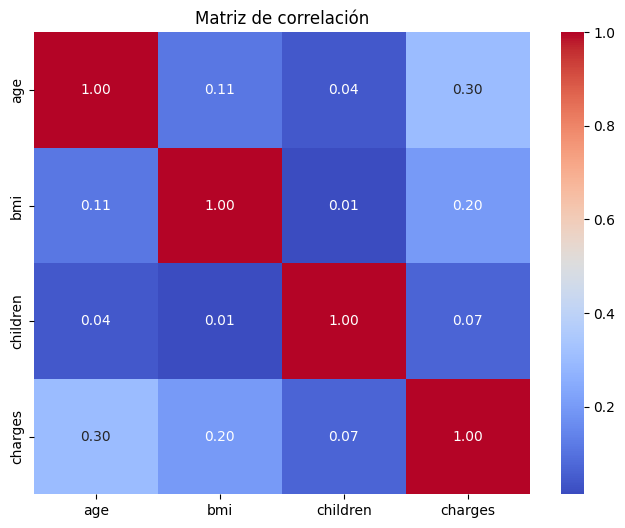

In [ ]:
#realizamos un mapa de calor para ver la correlacion que tienen nuestras variables numericas con la varible "charges"

corr = df.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Matriz de correlación")

plt.show()

**Interpretación:**  
Entre las variables numéricas, `age` es la que muestra la relación lineal positiva más clara con `charges`. `bmi` también presenta una asociación positiva, aunque más débil, mientras que `children` muestra una relación lineal baja con el costo médico. Esto indica que las variables numéricas por sí solas no explican completamente las diferencias en `charges`, por lo que conviene incorporar las variables categóricas al análisis.


**Relación entre `smoker` y `charges`**


In [ ]:
fig = px.box(
    df,
    x="smoker",
    y="charges",
    points="outliers",
    title="Costos médicos según condición de fumador"
)

fig.update_layout(
    width=700,
    height=500,
    xaxis_title="Fumador",
    yaxis_title="Charges",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True)
)

fig.show()


**Interpretación:**  
La condición de fumador muestra una separación clara en los costos médicos: las personas fumadoras tienden a presentar valores de `charges` considerablemente más altos. Esta variable aparece como una candidata importante para explicar o predecir los costos.


**Relación entre `bmi`, `charges` y condición de fumador**


In [ ]:
fig = px.scatter(
    df,
    x="bmi",
    y="charges",
    color="smoker",
    title="BMI y costos médicos según condición de fumador",
    opacity=0.7
)

fig.update_layout(
    width=800,
    height=500,
    xaxis_title="BMI",
    yaxis_title="Charges",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True)
)

fig.show()

**Interpretación:**  
La relación entre `bmi` y `charges` no es igual para todos los individuos. Al diferenciar por condición de fumador se aprecia que los costos elevados se concentran especialmente entre fumadores, y el BMI parece adquirir mayor importancia dentro de ese grupo.


**Conclusión de la exploración de datos**

La exploración muestra que los costos médicos no se distribuyen de manera uniforme y presentan una cola hacia valores altos. Entre las variables analizadas, la condición de fumador aparece como el factor con mayor diferenciación de costos, seguida por la edad y, en menor medida, el BMI. Los valores extremos de `charges` se conservarán inicialmente porque pueden representar casos reales de alto costo y contienen información relevante para el objetivo del proyecto.


### 1.5 Calidad de los datos

En esta sección realizamos un análisis del dataset para identificar posibles anomalías o inconsistencias en los datos.
Evaluaremos los siguientes aspectos clave:
* **Valores faltantes (nulos):** Comprobación de la integridad de los datos en todas las columnas.
* **Registros duplicados:** Detección de filas idénticas cargadas repetidamente.
* **Consistencia categórica:** Control de posibles errores de tipeo o variaciones en las etiquetas (`sex`, `smoker`, `region`).
* **Valores atípicos (outliers):** Inspección preliminar de rangos y valores extremos en las variables cuantitativas (`age`, `bmi`, `charges`).


#### 1.5.1 Valores faltantes

No se detectan valores nulos en ninguna de las siete variables. Las 1338 filas presentan información completa en todas las columnas, por lo que el dataset no requiere un tratamiento de datos faltantes en esta etapa.


In [ ]:
# 1. Control analítico de nulos
print("--- CONTROL DE VALORES NULOS ---")
print(df.isnull().sum())

--- CONTROL DE VALORES NULOS ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


#### 1.5.2 Registros duplicados

Se detectaron dos filas con valores idénticos en la totalidad de las variables del dataset. Aunque no existe una clave primaria que permita confirmar que corresponden a la misma persona, para evitar que una observación repetida influya dos veces en el análisis y en el entrenamiento del modelo, se decidió conservar una sola ocurrencia. El dataset resultante contiene 1337 registros.

In [ ]:
# 2. Control de duplicados exactos
print("\n--- CONTROL DE DUPLICADOS ---")
cant_duplicados = df.duplicated().sum()
print(f"Registros completamente duplicados detectados: {cant_duplicados}")
if cant_duplicados > 0:
    print("Muestra de filas duplicadas:")
    display(df[df.duplicated(keep=False)].head())


--- CONTROL DE DUPLICADOS ---
Registros completamente duplicados detectados: 1
Muestra de filas duplicadas:


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [ ]:
df = df.drop_duplicates().reset_index(drop=True).copy()

print(f"Cantidad de registros después de eliminar duplicados: {len(df)}")
print(f"Duplicados restantes: {df.duplicated().sum()}")

Cantidad de registros después de eliminar duplicados: 1337
Duplicados restantes: 0


#### 1.5.3 Categorías inconsistentes

**Interpretación:**  
Las categorías observadas son consistentes: `sex` contiene `female` y `male`; `smoker`, `yes` y `no`; y `region`, `southwest`, `southeast`, `northwest` y `northeast`. No se observan errores de escritura, espacios adicionales ni etiquetas inesperadas.


**Limitación del dataset:** el conjunto de datos no contiene una clave primaria ni un identificador único de beneficiario. Por este motivo, no es posible determinar con certeza absoluta si dos filas idénticas corresponden a una carga repetida o a personas distintas con las mismas características.

In [ ]:
#4. Consistencia en variables categóricas
print("\n--- VALORES ÚNICOS EN CATEGÓRICAS ---")
for col in ['sex', 'smoker', 'region']:
    print(f"Columna '{col}': {df[col].unique()}")



--- VALORES ÚNICOS EN CATEGÓRICAS ---
Columna 'sex': ['female' 'male']
Columna 'smoker': ['yes' 'no']
Columna 'region': ['southwest' 'southeast' 'northwest' 'northeast']


In [ ]:
# 4. Control rápido de límites lógicos
print("\n--- RANGOS DE VARIABLES NUMÉRICAS ---")
print(df[['age', 'bmi', 'charges']].describe().loc[['min', 'max']])


--- RANGOS DE VARIABLES NUMÉRICAS ---
      age    bmi      charges
min  18.0  15.96   1121.87390
max  64.0  53.13  63770.42801


#### 1.5.4 **Control complementario: cardinalidad y rangos lógicos**

Además de revisar las etiquetas, se controla cuántos valores distintos tiene cada variable y si los mínimos y máximos observados son compatibles con el significado de los datos.


In [ ]:
# Cardinalidad: cantidad de valores diferentes por variable
cardinalidad = pd.DataFrame({
    "Valores_unicos": df.nunique(),
    "Porcentaje_unico": (df.nunique() / len(df) * 100).round(2)
})

display(cardinalidad)


,Valores_unicos,Porcentaje_unico
age,47,3.52
sex,2,0.15
bmi,548,40.99
children,6,0.45
smoker,2,0.15
region,4,0.30
charges,1337,100.00


Las variables categóricas presentan una cardinalidad baja y esperable, lo cual facilita su posterior codificación. `age` y `children` también contienen un número acotado de valores posibles. Los rangos observados (`age` entre 18 y 64 años, `bmi` entre 15,96 y 53,13 y `charges` entre 1121,87 y 63770,43) no muestran valores imposibles a simple vista, aunque los extremos de `bmi` y `charges` requieren una revisión específica como posibles *outliers*.


#### 1.5.5 Valores atípicos (*outliers*)


`charges` presenta 139 valores superiores al límite establecido mediante el criterio IQR, equivalentes al 10,40 % de los registros. También se identificaron 9 posibles valores atípicos en `bmi`, equivalentes al 0,67 %. Estos casos no fueron eliminados porque pueden representar situaciones reales y resultan relevantes para el objetivo del proyecto.

In [ ]:
# Detección de posibles outliers mediante el criterio IQR
variables_numericas = ["age", "bmi", "children", "charges"]
resumen_outliers = []

for col in variables_numericas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    mascara = (df[col] < limite_inf) | (df[col] > limite_sup)
    cantidad = mascara.sum()

    resumen_outliers.append({
        "Variable": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "Limite_inferior": round(limite_inf, 2),
        "Limite_superior": round(limite_sup, 2),
        "Outliers": int(cantidad),
        "Porcentaje": round(cantidad / len(df) * 100, 2)
    })

resumen_outliers = pd.DataFrame(resumen_outliers)
display(resumen_outliers)


,Variable,Q1,Q3,Limite_inferior,Limite_superior,Outliers,Porcentaje
0,age,27.00,51.00,-9.00,87.00,0,0.00
1,bmi,26.29,34.70,13.67,47.32,9,0.67
2,children,0.00,2.00,-3.00,5.00,0,0.00
3,charges,4746.34,16657.72,-13120.72,34524.78,139,10.40


In [ ]:
# Boxplots para inspección visual de valores extremos
fig = make_subplots(
    rows=1, cols=4,
    subplot_titles=("Age", "BMI", "Children", "Charges")
)

for j, col in enumerate(["age", "bmi", "children", "charges"], start=1):
    fig.add_trace(go.Box(y=df[col], name=col), row=1, col=j)
    fig.update_yaxes(showgrid=True, row=1, col=j)
    fig.update_xaxes(showgrid=True, row=1, col=j)

fig.update_layout(
    width=1100,
    height=500,
    showlegend=False,
    title_text="Control visual de posibles outliers"
)

fig.show()


#### 1.5.6 Tipos de datos

- Verificar que cada columna tenga un tipo de dato coherente con su significado.
- Confirmar que las variables numéricas sean numéricas y las categóricas estén correctamente representadas.

**Interpretación:**  
Los tipos de datos son coherentes con el diccionario definido: `age` y `children` son enteros; `bmi` y `charges` son valores numéricos decimales; y `sex`, `smoker` y `region` están representadas como variables de tipo `object`. No se detectan conversiones evidentes necesarias por errores de tipo.


In [ ]:
# Verificación de tipos de datos
tipos = pd.DataFrame({
    "Tipo_de_dato": df.dtypes.astype(str),
    "Valores_no_nulos": df.notna().sum(),
    "Valores_unicos": df.nunique()
})

display(tipos)


,Tipo_de_dato,Valores_no_nulos,Valores_unicos
age,int64,1337,47
sex,object,1337,2
bmi,float64,1337,548
children,int64,1337,6
smoker,object,1337,2
region,object,1337,4
charges,float64,1337,1337


###**Conclusión de la calidad y preparación de los datos**

El dataset presenta una buena calidad general: no contiene valores faltantes, las variables poseen tipos de datos coherentes y las categorías presentan etiquetas consistentes.

Se detectó una fila completamente duplicada. Aunque el dataset no dispone de una clave primaria que permita comprobar que ambos registros correspondían a la misma persona, se decidió eliminar una de las dos filas debido a que coincidían exactamente en las siete variables disponibles. De esta manera, el conjunto utilizado para el modelado quedó conformado por 1337 registros.

También se identificaron posibles valores atípicos, principalmente en charges y bmi. Estos registros no fueron eliminados, ya que no presentan valores imposibles y pueden representar casos reales. En particular, los costos médicos elevados resultan relevantes para el objetivo del proyecto, orientado a anticipar situaciones de elevada siniestralidad.

##  2. Modelo Base

### 2.1 Preparación del data set para entrenar el modelo

In [ ]:
df_modelo = df.copy()

print(f"Registros utilizados para el modelado: {len(df_modelo)}")

Registros utilizados para el modelado: 1337


### 2.2 Codificar las variables categóricas

In [ ]:
df_encoded = pd.get_dummies(
    df_modelo,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


### 2.3 Separar variables predictoras y objetivo

In [ ]:
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (1337, 8)
Dimensiones de y: (1337,)


### 2.4 Dividir entrenamiento y prueba

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

Registros de entrenamiento: 1069
Registros de prueba: 268


### 2.5 Entrenar el modelo base

In [ ]:
from sklearn.linear_model import LinearRegression

modelo_base = LinearRegression()
modelo_base.fit(X_train, y_train)

y_pred = modelo_base.predict(X_test)

### 2.6 Evaluación del modelo base

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f} ({r2 * 100:.2f}%)")

MAE: $4,177.05
RMSE: $5,956.34
R²: 0.8069 (80.69%)


### Conclusión modelo actual:

El modelo de regresión lineal alcanzó un R² de 0,8069, por lo que explica aproximadamente el 80,69 % de la variabilidad observada en los costos médicos del conjunto de prueba. Si bien constituye un resultado inicial adecuado para un modelo base, todavía no alcanza la meta de R² ≥ 0,85 definida en los criterios de aceptación. En la siguiente etapa se evaluarán modelos no lineales, nuevas variables derivadas y ajustes de hiperparámetros.

## 3. Informe Técnico

Se realizó un análisis exploratorio del dataset compuesto originalmente por 1338 registros y siete variables. No se encontraron valores faltantes ni categorías inconsistentes. Se identificó una fila completamente duplicada, que fue eliminada para evitar que una misma observación influyera dos veces en el entrenamiento, por lo que el conjunto final quedó conformado por 1337 registros.

Mediante el criterio del rango intercuartílico se detectaron 9 posibles valores atípicos en bmi y 139 en charges. Estos casos no fueron eliminados porque pueden representar beneficiarios reales y resultan especialmente relevantes para el objetivo de anticipar costos médicos elevados.

Para desarrollar el modelo base se codificaron las variables categóricas mediante variables dummy y se dividieron los datos en un 80 % para entrenamiento y un 20 % para prueba. Se entrenó un modelo de regresión lineal que obtuvo un MAE de `$4.177,05`, un RMSE de `$5.956,34` y un R² de 0,8069.

El modelo explica aproximadamente el 80,69 % de la variabilidad de los costos médicos. Sin embargo, no alcanza todavía las metas definidas en los criterios de aceptación de R² ≥ 0,85 y MAE ≤ $3.000. En la siguiente etapa se evaluarán modelos no lineales, variables derivadas, interacciones entre factores —especialmente tabaquismo y obesidad— y ajustes de hiperparámetros.

## Modelo 2:

#EA3: Evidencia de aprendizaje 3 - Testeo del software; Práctica Profesionalizante 1

# Herramienta de pruebas – Evidencia 3
## Sistema predictivo de gastos médicos – Fénix Medical Tech
**Testeo de Software – Grupo 1**

Este notebook es el prototipo que usamos los 5 integrantes para ejecutar **todas las pruebas** (funcionales, seguridad y usabilidad) con la misma herramienta.

La carga de datos se hace en una **página web aparte**, creada con la librería Gradio. Al ejecutar el notebook se genera un link que abre el formulario en otra pestaña del navegador.

### Cómo usarlo
1. **Archivo → Guardar una copia en Drive** (así trabajás en tu copia).
2. **Entorno de ejecución → Ejecutar todas**. La primera vez tarda alrededor de un minuto porque instala Gradio.
3. Al final de la sección 3 aparece un link que termina en **gradio.live**. Hacé clic y se abre el sistema.
4. Buscá tu caso en la **Guía por caso** (al final de este notebook) y seguí los pasos.
5. Sacá una **captura** de la página donde se vean los datos y el mensaje del resultado.

**Importante:** el link funciona mientras el notebook esté abierto y ejecutándose. Si se corta, volvé a ejecutar la sección 3 y se genera un link nuevo.

### Secciones
0. Instalación de Gradio
1. Preparación del modelo (el mismo de la Evidencia 2)
2. Funciones del sistema: validación, estimación y clasificación
3. Interfaz web: carga, estimación, consulta y reporte

In [ ]:
# ===== 0. INSTALACIÓN DE GRADIO (librería para crear la interfaz web) =====
!pip install -q gradio

## 1. Preparación del modelo
Reproduce el modelo de la Evidencia 2. Si el entorno está bien, las métricas deben dar **MAE ≈ $4.177** y **R² ≈ 0,8069**.

El umbral de gasto elevado se tomó del EDA (límite superior de outliers de `charges`). Es una **propuesta del grupo** que debe confirmar el rol de auditoría.

In [ ]:
# ===== 1. PREPARACIÓN DEL MODELO (igual que en la Evidencia 2) =====
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Cargamos el dataset y eliminamos el registro duplicado
url = "https://raw.githubusercontent.com/federico2018lc/Estudio_Dataset_MedicalCostPersonal-Datasets_Kaggle/refs/heads/main/insurance.csv"
df = pd.read_csv(url)
df = df.drop_duplicates()

# Codificación one-hot y separación de variables
df_encoded = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]

# División 80/20 y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Métricas (deben coincidir con la Evidencia 2)
y_pred = modelo.predict(X_test)
print("Registros utilizados:", len(df))
print(f"MAE: ${mean_absolute_error(y_test, y_pred):,.2f}")
print(f"R²: {r2_score(y_test, y_pred):.4f}")

# Umbral de gasto elevado: límite superior de outliers de charges (Q3 + 1,5 x IQR), como en el EDA
q1 = df["charges"].quantile(0.25)
q3 = df["charges"].quantile(0.75)
UMBRAL = q3 + 1.5 * (q3 - q1)
print(f"Umbral de gasto elevado: ${UMBRAL:,.2f}")

Registros utilizados: 1337
MAE: $4,177.05
R²: 0.8069
Umbral de gasto elevado: $34,524.78


## 2. Funciones del sistema
Acá están las reglas del sistema: **validar** los datos, **estimar** el costo y **clasificar** el gasto. No hace falta modificar nada.

Al final se muestra el **valor de referencia** para CF-03: es el resultado correcto calculado directamente con el modelo, para comparar con lo que muestra la página.

In [ ]:
# ===== 2. FUNCIONES DEL SISTEMA =====

# Traducción de las opciones en español a los valores que usa el modelo
traduccion = {
    "masculino": "male", "femenino": "female",
    "sí": "yes", "no": "no",
    "sureste": "southeast", "suroeste": "southwest",
    "noreste": "northeast", "noroeste": "northwest",
}

def validar(edad, sexo, bmi, hijos, fumador, region):
    """Revisa los datos. Devuelve una lista con los errores encontrados (vacía si está todo bien)."""
    errores = []

    # Campos obligatorios
    if edad == "": errores.append("El campo Edad es obligatorio.")
    if sexo == "": errores.append("El campo Sexo es obligatorio.")
    if bmi == "": errores.append("El campo BMI es obligatorio.")
    if hijos == "": errores.append("El campo Hijos es obligatorio.")
    if fumador == "": errores.append("El campo Fumador es obligatorio.")
    if region == "": errores.append("El campo Región es obligatorio.")
    if errores:
        return errores

    # Edad: número entero entre 18 y 64
    if not edad.isdigit():
        errores.append("Edad: debe ser un número entero (ej: 45).")
    elif int(edad) < 18 or int(edad) > 64:
        errores.append("Edad fuera de rango: debe estar entre 18 y 64 años.")

    # BMI: número mayor a 0 (se acepta coma decimal)
    try:
        if float(bmi.replace(",", ".")) <= 0:
            errores.append("BMI: debe ser mayor a 0.")
    except ValueError:
        errores.append("BMI: debe ser un número (ej: 32,5).")

    # Hijos: número entero
    if not hijos.isdigit():
        errores.append("Hijos: debe ser un número entero (ej: 2).")

    return errores


def estimar(edad, sexo, bmi, hijos, fumador, region):
    """Arma la fila con las mismas columnas del modelo y devuelve el costo estimado."""
    fila = pd.DataFrame(0, index=[0], columns=X.columns)
    fila["age"] = edad
    fila["bmi"] = bmi
    fila["children"] = hijos
    if traduccion[sexo] == "male":
        fila["sex_male"] = 1
    if traduccion[fumador] == "yes":
        fila["smoker_yes"] = 1
    columna_region = "region_" + traduccion[region]
    if columna_region in fila.columns:      # "northeast" es la categoría de referencia
        fila[columna_region] = 1
    return modelo.predict(fila)[0]


def clasificar(costo):
    if costo > UMBRAL:
        return "GASTO ELEVADO"
    return "Normal"


# Valor de referencia para CF-03 (datos de CF-01)
referencia = estimar(45, "masculino", 32.5, 2, "sí", "sureste")
print(f"Valor de referencia CF-03: ${referencia:,.2f}")

Valor de referencia CF-03: $33,637.95


## 3. Interfaz web (Gradio)
La página tiene dos pestañas:
- **Carga y estimación:** completar los datos → **Confirmar carga** → **Estimar costo**.
- **Consulta y reporte:** elegir un filtro → **Mostrar** → **Generar reporte** (se descarga un archivo CSV).

El botón **Vaciar tabla** borra los beneficiarios cargados, para empezar cada caso de cero.

In [ ]:
# ===== 3. INTERFAZ WEB =====
import gradio as gr

COLUMNAS = ["Edad", "Sexo", "BMI", "Hijos", "Fumador", "Región", "Costo estimado", "Clasificación"]
tabla = pd.DataFrame(columns=COLUMNAS)


def confirmar_carga(edad, sexo, bmi, hijos, fumador, region):
    global tabla
    # Si una lista no se eligió, llega vacía (None); la pasamos a texto vacío
    edad, bmi, hijos = str(edad).strip(), str(bmi).strip(), str(hijos).strip()
    sexo, fumador, region = sexo or "", fumador or "", region or ""

    errores = validar(edad, sexo, bmi, hijos, fumador, region)
    if errores:
        mensaje = "ERROR: no se pudo cargar. Revisá:\n- " + "\n- ".join(errores)
    else:
        tabla.loc[len(tabla)] = [int(edad), sexo, float(bmi.replace(",", ".")), int(hijos),
                                 fumador, region, None, ""]
        mensaje = "CORRECTO: beneficiario cargado. Datos disponibles para la estimación."
    return mensaje, tabla


def estimar_costo():
    if len(tabla) == 0:
        return "ERROR: primero cargá un beneficiario con 'Confirmar carga'.", tabla
    i = len(tabla) - 1                     # último beneficiario cargado
    r = tabla.loc[i]
    costo = estimar(r["Edad"], r["Sexo"], r["BMI"], r["Hijos"], r["Fumador"], r["Región"])
    tabla.loc[i, "Costo estimado"] = round(costo, 2)
    tabla.loc[i, "Clasificación"] = clasificar(costo)
    mensaje = (f"Costo médico estimado: ${costo:,.2f}\n"
               f"Clasificación: {clasificar(costo)} (umbral: ${UMBRAL:,.2f})\n"
               "Es una predicción orientativa: requiere revisión del equipo de auditoría.")
    return mensaje, tabla


def vaciar_tabla():
    global tabla
    tabla = pd.DataFrame(columns=COLUMNAS)
    return "Tabla vacía. Podés empezar un caso nuevo.", tabla


def aplicar_filtro(filtro):
    estimados = tabla[tabla["Clasificación"] != ""]
    if filtro == "Solo gastos elevados":
        return estimados[estimados["Clasificación"] == "GASTO ELEVADO"]
    if filtro == "Solo normales":
        return estimados[estimados["Clasificación"] == "Normal"]
    return estimados


def generar_reporte(filtro):
    resultado = aplicar_filtro(filtro)
    resultado.to_csv("reporte_gastos.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
    return resultado, "reporte_gastos.csv"


with gr.Blocks(title="Fénix Medical Tech") as app:
    gr.Markdown("# Fénix Medical Tech\n### Sistema predictivo de gastos médicos")

    with gr.Tab("Carga y estimación"):
        with gr.Row():
            edad = gr.Textbox(label="Edad", placeholder="ej: 45")
            sexo = gr.Dropdown(["masculino", "femenino"], label="Sexo")
            bmi = gr.Textbox(label="BMI", placeholder="ej: 32,5")
        with gr.Row():
            hijos = gr.Textbox(label="Hijos", placeholder="ej: 2")
            fumador = gr.Dropdown(["sí", "no"], label="Fumador")
            region = gr.Dropdown(["sureste", "suroeste", "noreste", "noroeste"], label="Región")
        with gr.Row():
            boton_cargar = gr.Button("Confirmar carga", variant="primary")
            boton_estimar = gr.Button("Estimar costo")
            boton_vaciar = gr.Button("Vaciar tabla")
        mensaje = gr.Textbox(label="Mensaje del sistema", lines=3)
        tabla_vista = gr.Dataframe(value=tabla, label="Beneficiarios cargados")

    with gr.Tab("Consulta y reporte"):
        filtro = gr.Radio(["Todos", "Solo gastos elevados", "Solo normales"], value="Todos", label="Filtro")
        with gr.Row():
            boton_mostrar = gr.Button("Mostrar", variant="primary")
            boton_reporte = gr.Button("Generar reporte")
        tabla_filtrada = gr.Dataframe(label="Resultados")
        archivo = gr.File(label="Reporte (CSV)")

    boton_cargar.click(confirmar_carga, [edad, sexo, bmi, hijos, fumador, region], [mensaje, tabla_vista])
    boton_estimar.click(estimar_costo, None, [mensaje, tabla_vista])
    boton_vaciar.click(vaciar_tabla, None, [mensaje, tabla_vista])
    boton_mostrar.click(aplicar_filtro, filtro, tabla_filtrada)
    boton_reporte.click(generar_reporte, filtro, [tabla_filtrada, archivo])

# share=True genera el link público (gradio.live); inline=False hace que se abra fuera de Colab
app.launch(share=True, inline=False, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4468247b7023ed996c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Guía por caso
Antes de cada caso tocá **Vaciar tabla** en la página, para empezar de cero.

| ID | Qué hacer en la página | Aprobado si… |
|---|---|---|
| **CF-01** | Cargar edad 45, masculino, BMI 32,5, hijos 2, fumador sí, sureste → **Confirmar carga** | Aparece "CORRECTO: beneficiario cargado…" y los 6 valores se ven en la tabla |
| **CF-02** | Cargar femenino, BMI 27,4, hijos 1, fumador no, noroeste, **sin edad** → **Confirmar carga** | Aparece "El campo Edad es obligatorio" y no se agrega nada a la tabla |
| **CF-03** | Cargar los datos de CF-01 → **Confirmar carga** → **Estimar costo** | El costo es igual al valor de referencia de la sección 2 |
| **CF-04** | Cargar edad 60, masculino, BMI 40, hijos 0, fumador sí, sureste → **Confirmar carga** → **Estimar costo** | Clasificación: **GASTO ELEVADO** |
| **CF-05** | Cargar y estimar CF-04 y además (25, femenino, 22, 0, no, noreste) y (38, masculino, 28,4, 1, no, suroeste). En la pestaña **Consulta y reporte**: filtro "Solo gastos elevados" → **Mostrar** → **Generar reporte** | Solo aparece el caso elevado y el reporte descargado tiene lo mismo |
| **CF-06** | Datos de CF-01 cambiando la edad a 17, 18, 64 y 65 (una carga por vez) | Rechaza 17 y 65 con mensaje de rango; acepta 18 y 64 |
| **CF-07** | Datos de CF-01 con edad **cuarenta** | Aparece "Edad: debe ser un número entero" |
| **CS-01** | Edad `<script>alert(1)</script>` y BMI `1; DROP TABLE`, el resto como CF-01 | Rechaza los dos campos con mensaje; no se abre ninguna ventana ni se produce un error del sistema |
| **CU-01** | Mandarle el link al participante con los datos de CF-01. Pedirle que cargue y estime sin ayuda. Medir el tiempo con el celular y después hacerle las 3 preguntas | Lo hace solo en menos de 2 minutos y entiende los mensajes |

## ¿Qué hago si algo falla?
Hay un **bug** cuando el **resultado obtenido es distinto del esperado**.
1. En el documento, poné **Estado: Fallido** en ese caso.
2. Avisá al grupo y agregá una fila en la tabla de bugs (punto 5), indicando: qué falla, en qué caso, qué datos usaste, qué esperabas y qué pasó.
3. **Severidad:** Crítica (bloquea todo) · Alta (función principal mal) · Media · Baja (detalle).
4. Cuando se corrige, **se vuelve a ejecutar el caso** (repetición de prueba). Si pasa: **Estado: Cerrado / ¿Solucionado?: Sí**.

**BUG-01 y BUG-02:** este prototipo los soluciona, porque ahora hay formulario de carga y las opciones en español se traducen a las del modelo. Cuando CF-01 dé Aprobado, los dos pasan a **Cerrado / Sí**.